# Laboratory Work #1 — Monte Carlo Policy Evaluation

**Environment:** TinyChain (states A, B, C, TERMINAL), fixed policy, discount factor $\gamma = 0.9$.

**Goal:** estimate $V_\pi(s) = \mathbb{E}_\pi[G_t \mid S_t = s]$ with **first-visit Monte Carlo** from sampled complete episodes, and compare the estimates with the exact values computed analytically.

## 1. Starter code — environment

In [7]:
import random
import matplotlib.pyplot as plt
from collections import defaultdict

GAMMA = 0.9
STATES = ("A", "B", "C")


def generate_episode(rng):
    state = "A"
    episode = []
    while state != "TERMINAL":
        if state == "A":
            next_state, reward = ("B", 0) if rng.random() < 0.8 else ("TERMINAL", 0)
        elif state == "B":
            next_state, reward = ("C", 1) if rng.random() < 0.5 else ("TERMINAL", 1)
        else:
            next_state, reward = "TERMINAL", 3
        episode.append((state, reward, next_state))
        state = next_state
    return episode


rng = random.Random(0)
for _ in range(5):  # a few sample episodes
    print(generate_episode(rng))

[('A', 0, 'TERMINAL')]
[('A', 0, 'B'), ('B', 1, 'C'), ('C', 3, 'TERMINAL')]
[('A', 0, 'B'), ('B', 1, 'TERMINAL')]
[('A', 0, 'B'), ('B', 1, 'TERMINAL')]
[('A', 0, 'B'), ('B', 1, 'C'), ('C', 3, 'TERMINAL')]


## 2. First-visit Monte Carlo policy evaluation (completed TODOs)

The return is computed **backwards** through the episode with $G_t = R_{t+1} + \gamma\, G_{t+1}$ (starting from $G_T = 0$), which equals $G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$.

`state_returns` is therefore built in reverse time order. Iterating over it `reversed` walks forward in time again, so the first time a state is seen there is its **first occurrence** in the episode. Only that return is recorded.

In [8]:
def first_visit_mc(num_episodes, gamma=GAMMA, seed=42):
    rng = random.Random(seed)
    returns = defaultdict(list)
    for _ in range(num_episodes):
        episode = generate_episode(rng)
        G = 0.0
        state_returns = []
        for state, reward, next_state in reversed(episode):
            G = reward + gamma * G              # TODO 1: update discounted return G
            state_returns.append((state, G))    # TODO 2: append (state, G) to state_returns
        seen = set()
        for state, G in reversed(state_returns):
            if state in seen:                   # TODO 3: use only first occurrence of each state
                continue                        # TODO 3: skip repeated visits
            seen.add(state)                     # TODO 3: mark state as seen
            returns[state].append(G)            # TODO 4: append return to returns[state]
    return {s: sum(returns[s]) / len(returns[s]) if returns[s] else 0.0 for s in STATES}  # TODO 5: return dictionary of mean returns for A, B, C


for n in (10, 100, 1000, 10000):
    print(n, first_visit_mc(n))

10 {'A': 2.268, 'B': 2.8000000000000003, 'C': 3.0}
100 {'A': 1.7253, 'B': 2.3666666666666667, 'C': 3.0}
1000 {'A': 1.68093, 'B': 2.3001231527093595, 'C': 3.0}
10000 {'A': 1.691469, 'B': 2.337574626865672, 'C': 3.0}


**Sanity check of the return computation** on a single episode A→B→C: $G_C = 3$, $G_B = 1 + 0.9 \cdot 3 = 3.7$, $G_A = 0 + 0.9 \cdot 3.7 = 3.33$.

In [9]:
episode = [("A", 0, "B"), ("B", 1, "C"), ("C", 3, "TERMINAL")]
G = 0.0
for state, reward, _ in reversed(episode):
    G = reward + GAMMA * G
    print(f"G({state}) = {G:.2f}")

G(C) = 3.00
G(B) = 3.70
G(A) = 3.33


## 3. Analytical (true) values

Bellman expectation equation: $V(s) = \sum_{s'} P(s' \mid s)\,[R + \gamma V(s')]$, with $V(\text{TERMINAL}) = 0$.

- $V(C) = 3$
- $V(B) = 0.5\,(1 + 0.9 \cdot 3) + 0.5\,(1 + 0) = 1.85 + 0.5 = 2.35$
- $V(A) = 0.8\,(0 + 0.9 \cdot 2.35) + 0.2\,(0 + 0) = 0.8 \cdot 2.115 = 1.692$

In [10]:
def true_values(gamma=GAMMA):
    V = {"TERMINAL": 0.0}
    V["C"] = 1.0 * (3 + gamma * V["TERMINAL"])
    V["B"] = 0.5 * (1 + gamma * V["C"]) + 0.5 * (1 + gamma * V["TERMINAL"])
    V["A"] = 0.8 * (0 + gamma * V["B"]) + 0.2 * (0 + gamma * V["TERMINAL"])
    return {s: V[s] for s in STATES}


V_true = true_values()
V_mc = first_visit_mc(10_000)
print(f"{'State':<6}{'MC estimate':>14}{'True value':>14}{'Abs error':>12}")
for s in STATES:
    print(f"{s:<6}{V_mc[s]:>14.4f}{V_true[s]:>14.4f}{abs(V_mc[s] - V_true[s]):>12.4f}")

State    MC estimate    True value   Abs error
A             1.6915        1.6920      0.0005
B             2.3376        2.3500      0.0124
C             3.0000        3.0000      0.0000


## 4. Convergence with the number of episodes

In [11]:
episode_counts = [10, 50, 100, 500, 1_000, 5_000, 10_000, 50_000]

print(f"{'Episodes':>9} | " + " | ".join(f"V({s})   err  " for s in STATES))
history = {s: [] for s in STATES}
for n in episode_counts:
    V_n = first_visit_mc(n)
    row = []
    for s in STATES:
        history[s].append(V_n[s])
        row.append(f"{V_n[s]:.3f} {abs(V_n[s] - V_true[s]):.3f}")
    print(f"{n:>9} | " + " | ".join(row))

 Episodes | V(A)   err   | V(B)   err   | V(C)   err  
       10 | 2.268 0.576 | 2.800 0.450 | 3.000 0.000
       50 | 1.759 0.067 | 2.383 0.033 | 3.000 0.000
      100 | 1.725 0.033 | 2.367 0.017 | 3.000 0.000
      500 | 1.645 0.047 | 2.326 0.024 | 3.000 0.000
     1000 | 1.681 0.011 | 2.300 0.050 | 3.000 0.000
     5000 | 1.701 0.009 | 2.346 0.004 | 3.000 0.000
    10000 | 1.691 0.001 | 2.338 0.012 | 3.000 0.000
    50000 | 1.690 0.002 | 2.343 0.007 | 3.000 0.000


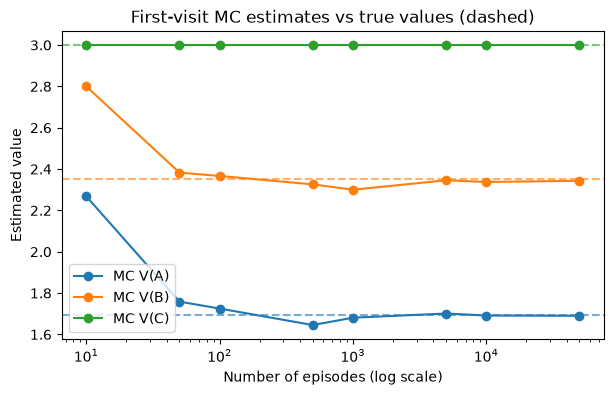

In [12]:
# Optional plot (requires matplotlib: pip install matplotlib)
try:
    fig, ax = plt.subplots(figsize=(7, 4))
    for s in STATES:
        line, = ax.plot(episode_counts, history[s], marker="o", label=f"MC V({s})")
        ax.axhline(V_true[s], linestyle="--", color=line.get_color(), alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("Number of episodes (log scale)")
    ax.set_ylabel("Estimated value")
    ax.set_title("First-visit MC estimates vs true values (dashed)")
    ax.legend()
    plt.show()
except ImportError:
    print("matplotlib not installed — skipping plot.")

## 5. Discussion

**Reward vs. return vs. state value.**
- *Reward* $R_{t+1}$ is the immediate scalar signal from one transition (e.g. 3 for C → TERMINAL).
- *Discounted return* $G_t$ is the (random) discounted sum of all future rewards in **one particular episode** from time $t$ — e.g. from A along A→B→C it is $0 + 0.9\cdot1 + 0.81\cdot3 = 3.33$, but along A→TERMINAL it is 0.
- *State value* $V_\pi(s)$ is the **expected** return from $s$ under $\pi$ — the average over all possible episodes (for A it is 1.692).

**Comparison with analytical values.** With 10,000 episodes the MC estimates agree with the true values (3, 2.35, 1.692) to roughly two decimal places; the error shrinks roughly as $1/\sqrt{N}$ as more episodes are used. $V(C)$ is exact from the start because C always yields return 3 (zero variance). A and B have random outcomes and so show sampling noise. Note A is visited in every episode, while B is reached in only ~80% and C in ~40% of them, so the estimates for C and B use fewer samples.

**Why Monte Carlo is model-free.** The algorithm never uses the transition probabilities (0.8, 0.5, …) or the reward function. It only needs sampled experience $(s, r, s')$ from interacting with the environment — `first_visit_mc` only calls `generate_episode` and looks at the sampled rewards. The analytical solution in Section 3, by contrast, requires the full model.

**Why it waits for complete episodes.** MC estimates $V(s)$ from the actual return $G_t$, which depends on *all* rewards until termination. $G_t$ is unknown until the episode reaches TERMINAL, so updates can only be made after the episode ends. (MC does not bootstrap — it doesn't use estimates of other states' values — unlike TD methods, which can update after each step.) This also means MC only works for episodic tasks.